In [13]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [14]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense


In [15]:
# Step 2: Load dataset
print("Loading MNIST dataset...")

(x_train, y_train), (x_test, y_test) = mnist.load_data()

Loading MNIST dataset...


In [16]:
# Step 3: Use a smaller subset for faster training
x_train = x_train[:12000]
y_train = y_train[:12000]

x_test = x_test[:2000]
y_test = y_test[:2000]
print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

Training images: (12000, 28, 28)
Testing images: (2000, 28, 28)


In [17]:
# Step 4: Normalize and reshape images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

In [18]:
# Step 5: Define CNN model
model = Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    Conv2D(16, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(32, activation="relu"),
    Dense(10, activation="softmax")
])

In [19]:
# Step 6: Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_1 (Conv2D)           (None, 26, 26, 16)        160       
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 13, 13, 16)       0         
 2D)                                                             
                                                                 
 flatten_1 (Flatten)         (None, 2704)              0         
                                                                 
 dense_2 (Dense)             (None, 32)                86560     
                                                                 
 dense_3 (Dense)             (None, 10)                330       
                                                                 
Total params: 87,050
Trainable params: 87,050
Non-trainable params: 0
__________________________________________________

In [20]:
#Step 7: Train model
print("\nTraining CNN model...")

history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


Training CNN model...
Epoch 1/3
85/85 [==============================] - 1s 4ms/step - loss: 0.8027 - accuracy: 0.7865 - val_loss: 0.3684 - val_accuracy: 0.8992
Epoch 2/3
85/85 [==============================] - 0s 3ms/step - loss: 0.2986 - accuracy: 0.9158 - val_loss: 0.2873 - val_accuracy: 0.9158
Epoch 3/3
85/85 [==============================] - 0s 3ms/step - loss: 0.2262 - accuracy: 0.9360 - val_loss: 0.2403 - val_accuracy: 0.9308


In [21]:
# Step 8: Evaluate model
print("\nEvaluating model...")

test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")



Evaluating model...
Test Loss: 0.2864
Test Accuracy: 91.45 %


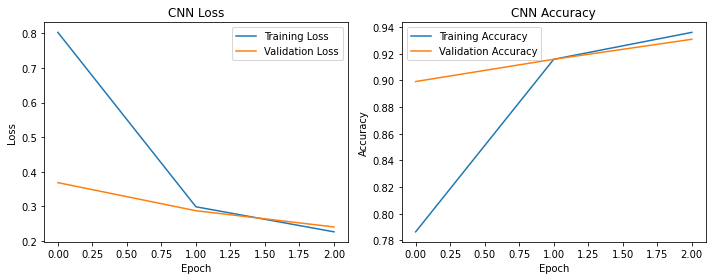

In [22]:
# Step 9: Plot loss and accuracy
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


Predicted digit: 7
Actual digit: 7


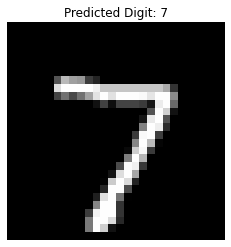

In [23]:
# Step 10: Predict a test image
prediction = model.predict(x_test[:1], verbose=0)

predicted_digit = np.argmax(prediction[0])
actual_digit = y_test[0]

print("\nPredicted digit:", predicted_digit)
print("Actual digit:", actual_digit)

plt.imshow(x_test[0].squeeze(), cmap="gray")
plt.title("Predicted Digit: " + str(predicted_digit))
plt.axis("off")
plt.show()
